# v102 ellipses: elliptical BEM contacts against Hertz, alpha 1-100

**Question.** Does the SlipPY BEM, through `slippy_bridge`, reproduce the Hertz ellipse (approach, p0,
semi-axes, ellipticity, orientation) of two bodies given with their own radii and the angle between them,
over `alpha = R_y/R_x` 1-100, and the worked contacts of Hamrock and Brewe (1983) Table 5 (PDF p. 6)?

**Systems.** Two steel cylinders R 10 mm crossed at `theta = arccos((alpha - 1)/(alpha + 1))` (Table 1
alphas, PDF p. 4), 50 N; Table 5: wheel on rail, ball on plane, ball on the outer ring (concave groove).
**Reference.** r02 `hertz` (SlipPY `hertz_full`) at the BEM load. Spatial kernel, interference control,
principal grid, `b/h` 16 and 32 asked (v104's rule), half-length 2.

**Criteria (README section 6, fixed before the run).** v101's C1 (approach 0.5 %), C3 (p0 `M^-3/2`),
C4 (semi-axes `1/M`); E1 `k = a/b` within `2/M`; E2 orientation of the BEM major axis within `h/a` rad;
T5: Table 5 values within the v101 tolerance plus half a unit of the printed digit. Judged on the spatial
kernel at `b/h >= 16` with the Hertz reference in range (a/R <= 0.1 per body); RECORD otherwise.

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v100_dry_contact.v102_hertz_ellipses import study

out = study.run()
cols = (("literature_case", "case", "s"), ("b_over_h", "b/h", ".1f"), ("id", "id", "s"), ("quantity", "quantity", "s"),
        ("measured", "BEM", ".6g"), ("reference", "reference", ".6g"), ("rel_err", "err [%]", "+.4f", 100.0),
        ("tol", "tol [%]", ".3f", 100.0), ("verdict", "verdict", "s"))

## 1. Alpha sweep (crossed cylinders, Table 1 alphas)

                     case   b/h  id                    quantity          BEM    reference    err [%]  tol [%]  verdict
-------------------------  ----  --  --------------------------  -----------  -----------  ---------  -------  -------
  hamrock_brewe_t1_alpha1  19.4  C1                       delta   2.1941e-06  2.19443e-06    -0.0153    0.500     PASS
  hamrock_brewe_t1_alpha1  19.4  C2                        load      50.0115           50    +0.0230        -   RECORD
  hamrock_brewe_t1_alpha1  19.4  C3                          p0  1.08823e+09  1.08815e+09    +0.0077    0.413     PASS
  hamrock_brewe_t1_alpha1  19.4  C4                           a  0.000147235  0.000148136    -0.6085    2.575     PASS
  hamrock_brewe_t1_alpha1  19.4  C4                           b  0.000147235  0.000148136    -0.6085    2.575     PASS
  hamrock_brewe_t1_alpha1  19.4  C5                       eps_p    0.0036417            0    +0.3642        -   RECORD
  hamrock_brewe_t1_alpha1  19.4  E1             

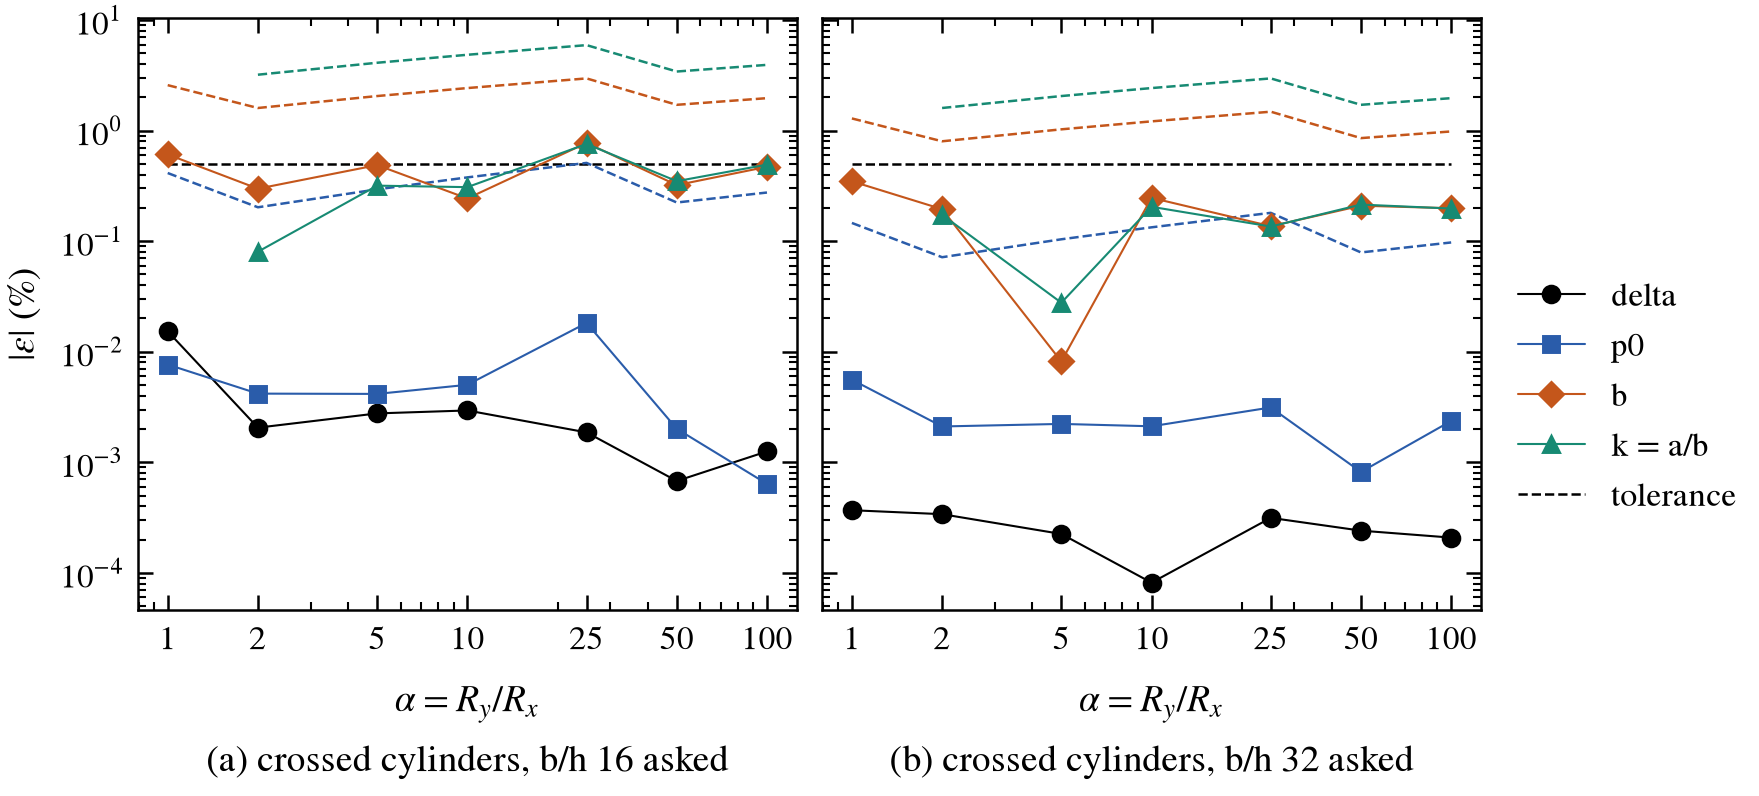

In [2]:
print(format_table(cols, [r for r in out["check"] if "_t1_" in r["literature_case"] and r["id"] not in ("L1", "L2")]))
display(Image(filename=str(out["figures"][0])))

## 2. Hamrock and Brewe Table 5

                                    case   b/h  id                    quantity           BEM    reference   err [%]  tol [%]  verdict
----------------------------------------  ----  --  --------------------------  ------------  -----------  --------  -------  -------
          hamrock_brewe_t5_wheel_on_rail  22.1  C1                       delta   0.000105915  0.000105919   -0.0033    0.500     PASS
          hamrock_brewe_t5_wheel_on_rail  22.1  C2                        load        100005       100000   +0.0049        -   RECORD
          hamrock_brewe_t5_wheel_on_rail  22.1  C3                          p0   1.16612e+09    1.166e+09   +0.0103    0.341     PASS
          hamrock_brewe_t5_wheel_on_rail  22.1  C4                           a    0.00758666   0.00759521   -0.1125    2.264     PASS
          hamrock_brewe_t5_wheel_on_rail  22.1  C4                           b    0.00538602   0.00539167   -0.1048    2.264     PASS
          hamrock_brewe_t5_wheel_on_rail  22.1  C5            

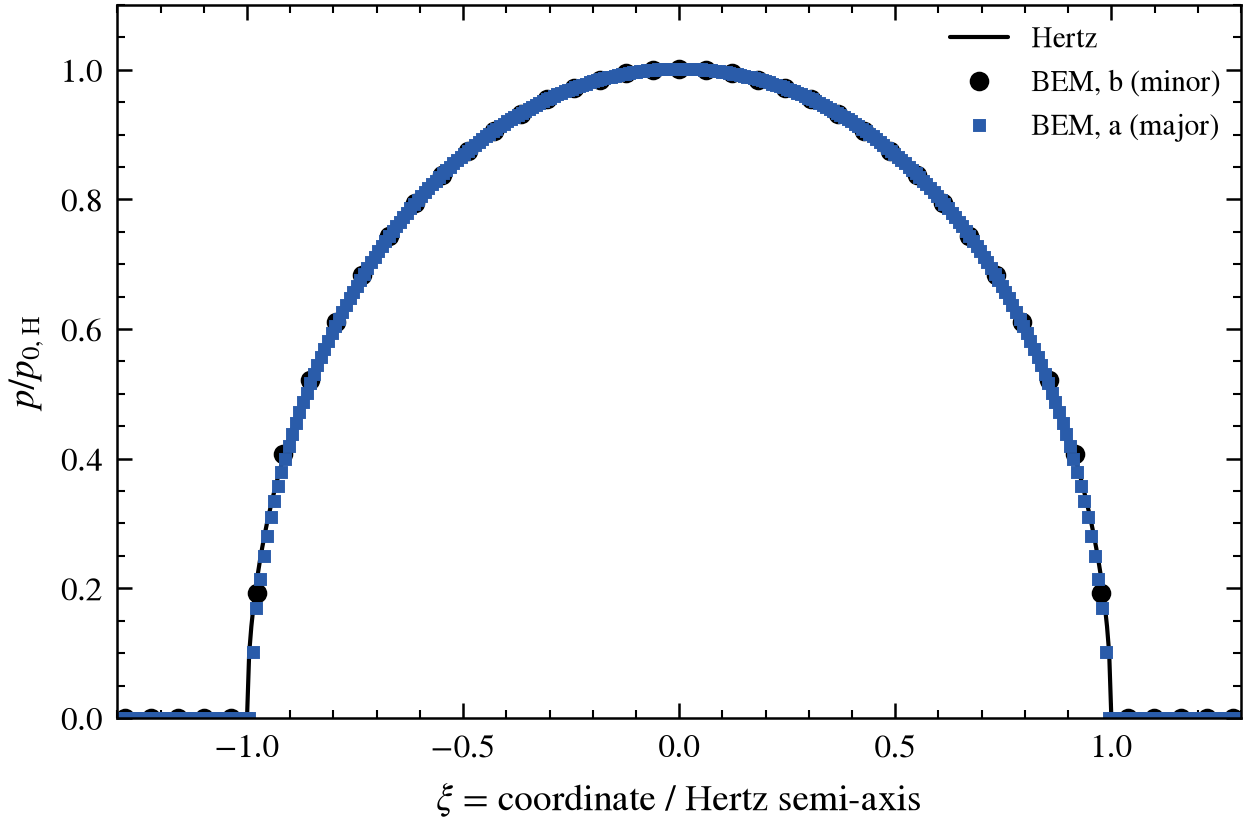

In [3]:
print(format_table(cols, [r for r in out["check"] if "_t5_" in r["literature_case"] and r["id"] not in ("L1", "L2")]))
display(Image(filename=str(out["figures"][1])))

## 3. Verdict

In [4]:
judged = [r for r in out["check"] if r["verdict"] != "RECORD"]
misses = [r for r in judged if r["verdict"] == "MISS"]
print(f"judged {len(judged)}, PASS {len(judged) - len(misses)}, MISS {len(misses)}")
print(format_table(cols, misses))

judged 138, PASS 130, MISS 8
                          case   b/h  id            quantity          BEM  reference   err [%]  tol [%]  verdict
------------------------------  ----  --  ------------------  -----------  ---------  --------  -------  -------
hamrock_brewe_t5_wheel_on_rail  22.1  T5              2b BEM    0.0107719   0.012801  -15.8515    2.268     MISS
hamrock_brewe_t5_wheel_on_rail  22.1  T5              2a BEM    0.0151731   0.018032  -15.8547    2.267     MISS
hamrock_brewe_t5_wheel_on_rail  22.1  T5           delta BEM  0.000105912    8.9e-05  +19.0023    1.062     MISS
hamrock_brewe_t5_wheel_on_rail  22.1  T5  sigma_max = p0 BEM   1.1661e+09   8.27e+08  +41.0041    0.401     MISS
hamrock_brewe_t5_wheel_on_rail  44.2  T5              2b BEM    0.0107667   0.012801  -15.8918    1.136     MISS
hamrock_brewe_t5_wheel_on_rail  44.2  T5              2a BEM    0.0151691   0.018032  -15.8769    1.135     MISS
hamrock_brewe_t5_wheel_on_rail  44.2  T5           delta BEM  0.000